# Heart Disease Prediction System

## Setup: Running This Notebook From Scratch
1. Check Python: `python --version` (built on Python 3.12.3; 3.10-3.13 should work).
2. Create a virtual environment: `python -m venv venv` (Windows) or `python3 -m venv venv` (macOS/Linux).
3. Activate it: `venv\Scripts\activate` (Windows) or `source venv/bin/activate` (macOS/Linux).
4. Install packages: `pip install numpy pandas scikit-learn prettytable matplotlib seaborn jupyter`
5. Put `processed_cleveland.data` (from the UCI zip) in the same folder as this notebook.
6. Run `jupyter notebook`, open this file and choose **Kernel -> Restart & Run All**.

## What is different from the Titanic notebook (and why)
This notebook follows the **same 10-step flow** as the Titanic reference. Only the changes that the new dataset genuinely requires were made:

| Change | Why it was needed |
|---|---|
| Data has **no header** and uses `?` for missing values | Column names are added in code and `?` is read as NaN (Step 2) |
| Target `num` has values 0-4 | Converted to binary: 0 = No disease, 1-4 = Disease (Step 3.2) |
| **Exactly 4 inputs** selected using evidence | Task constraint; selection is justified with correlation, Random Forest importance and cross-validation (Step 4) |
| **Two numeric inputs** (max heart rate, ST depression) | Titanic had only categorical inputs. Numeric values are left as numbers, but must be **scaled** (new Step 6.3) so SVC is not dominated by large values |
| Split is **stratified and shuffled** | Keeps the disease/no-disease ratio equal in train and test sets |
| Added **5-fold cross-validation** to the model comparison | Only 303 rows, so a single 20% test split (61 rows) is a noisy estimate |

## Introduction

##### **Definition** A binary classification ML task that predicts whether a patient has heart disease (1) or not (0) from a few clinical measurements.
##### **Application** Used for learning data science and as an example of a screening-support tool. It is an **educational project, not a medical device**.

## Input and Output

### Inputs (Features / Attributes) - only 4 selected

| **Input Feature/Attribute** | **Original column** | **Possible Values** |
| --- | --- | --- |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic |
| **MaxHeartRate** | `thalach` | Number (about 70 - 210 bpm) |
| **ExerciseAngina** | `exang` | Yes, No |
| **STDepression** | `oldpeak` | Number (0 - about 6.2) |

### Output (Prediction)

| **Output Attribute** | **Possible Values** |
| --- | --- |
| **HeartDisease** | Yes, No |

## Developer & System Information

| | |
| --- | --- |
| **Developer Name** | *(write your name here)* |
| **Program Name** | heart_disease_project |
| **IDE** | Jupyter Notebook |
| **Programming Language** | Python 3.12.3 |
| **Libraries** | NumPy 2.4.4, Pandas 3.0.2, Pickle (built-in), scikit-learn 1.8.0, PrettyTable, Matplotlib, Seaborn |
| **Dataset** | UCI Heart Disease (Cleveland), https://archive.ics.uci.edu/dataset/45/heart+disease |
| **Date of Completion** | 18-Oct-2026 |

## Table of Content
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
  - Step 3.1: Understand Sample Data
  - Step 3.2: Pre-process Sample Data
  - Step 3.3: Visualize Heart Disease Rate by the Candidate Features
- Step 4: Feature Extraction (selecting the 4 input attributes)
- Step 5: Label Encoding the Sample Data
  - Step 5.1: Train the Label Encoders
  - Step 5.2: Label Encode the Output
  - Step 5.3: Label Encode the Input
- Step 6: Execute the Training Phase
  - Step 6.1: Splitting Sample Data into Training Data and Testing Data
  - Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data
  - Step 6.3: Scale the Numeric Features (NEW)
  - Step 6.4: Train the Support Vector Classifier
  - Step 6.5: Save the Trained Model
  - Step 6.6: Compare SVC vs. Logistic Regression vs. Decision Tree
- Step 7: Execute the Testing Phase
  - Step 7.1 - 7.5: Split, load model, predict, accuracy, detailed metrics
- Step 8: Execute the Application Phase
- Step 9: Execute the Feedback Phase
- Step 10: Deploy Your Model as a Public Web App

## Code - Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose of this code:
----------------------
Imports the libraries for data handling, preprocessing, model training,
evaluation, plotting and saving/loading the model.
"""
import numpy as np                      # arrays and math
import pandas as pd                     # DataFrames
import pickle                           # save / load trained objects

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn import svm
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier   # used ONLY to rank feature importance in Step 4
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data

In [2]:
"""
Purpose of this section:
-------------------------
Loads the Cleveland heart-disease file into a DataFrame.
- The file has NO header row, so we supply the 14 column names.
- Missing values are written as '?', so na_values="?" turns them into NaN.
"""
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

sample_data = pd.read_csv("processed_cleveland.data", header=None,
                          names=column_names, na_values="?")

print("\n\nSample Data (first 10 rows):")
print("============================\n")
pd.set_option("display.max_rows", 20, "display.max_columns", None)
print(sample_data.head(10))
print("\nShape (rows, columns):", sample_data.shape)



Sample Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3    3.0  0.

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose of this section:
-------------------------
1. Print attribute names and number of instances.
2. Show data types, missing values and the distribution of the output column.
"""
print("\n\nAttributes in Sample Data:")
print("==========================\n")
print(sample_data.columns)

print("\n\nNumber of Instances in Sample Data:", sample_data["age"].count())
print("========================================\n")

print("Missing values per attribute (only columns with missing values):")
missing = sample_data.isna().sum()
print(missing[missing > 0])

print("\nOriginal output column 'num' (0 = healthy, 1-4 = increasing severity):")
print(sample_data["num"].value_counts().sort_index())

print("\nSummary statistics of the numeric attributes:")
print(sample_data[["age", "trestbps", "chol", "thalach", "oldpeak"]].describe().round(2))



Attributes in Sample Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Sample Data: 303

Missing values per attribute (only columns with missing values):
ca      4
thal    2
dtype: int64

Original output column 'num' (0 = healthy, 1-4 = increasing severity):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Summary statistics of the numeric attributes:
          age  trestbps    chol  thalach  oldpeak
count  303.00    303.00  303.00   303.00   303.00
mean    54.44    131.69  246.69   149.61     1.04
std      9.04     17.60   51.78    22.88     1.16
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.50     0.00
50%     56.00    130.00  241.00   153.00     0.80
75%     61.00    140.00  275.00   166.00     1.60
max     77.00    200.00  564.00   202.00     6.20


#### Step 3.2: Pre-process Sample Data
Three preprocessing actions are required for this dataset:
1. **Missing values**: `?` already became NaN in Step 2. Check which columns are affected.
2. **Binary output**: `num` has 5 levels (0-4). The task is *has disease or not*, so 0 becomes **No** and 1-4 become **Yes**.
3. **Readable categories**: `cp` and `exang` are stored as codes. They are converted to text labels (like "First/Second/Third" in the Titanic data) so Label Encoding in Step 5 works exactly like the reference notebook.

In [4]:
"""
Purpose of this section:
-------------------------
Cleans the data so it is ready for encoding and training.
"""
preprocessed_data = sample_data.copy()

# 1. Missing values: which rows are affected?
rows_with_missing = preprocessed_data[preprocessed_data.isna().any(axis=1)]
print("Rows with a missing value:", len(rows_with_missing))
print("Columns affected:", list(preprocessed_data.columns[preprocessed_data.isna().any()]))

# 2. Binary output: 0 -> No, 1..4 -> Yes
preprocessed_data["HeartDisease"] = np.where(preprocessed_data["num"] > 0, "Yes", "No")

# 3. Readable text labels for the two categorical candidates
chest_pain_labels = {1: "Typical Angina", 2: "Atypical Angina", 3: "Non-anginal Pain", 4: "Asymptomatic"}
yes_no_labels = {0: "No", 1: "Yes"}
preprocessed_data["cp"] = preprocessed_data["cp"].astype(int).map(chest_pain_labels)
preprocessed_data["exang"] = preprocessed_data["exang"].astype(int).map(yes_no_labels)

print("\nOutput distribution after conversion:")
print(preprocessed_data["HeartDisease"].value_counts())
print("\nChest pain categories:")
print(preprocessed_data["cp"].value_counts())

Rows with a missing value: 6
Columns affected: ['ca', 'thal']

Output distribution after conversion:
HeartDisease
No     164
Yes    139
Name: count, dtype: int64

Chest pain categories:
cp
Asymptomatic        144
Non-anginal Pain     86
Atypical Angina      50
Typical Angina       23
Name: count, dtype: int64


#### Step 3.3: Visualize Heart Disease Rate by the Candidate Features

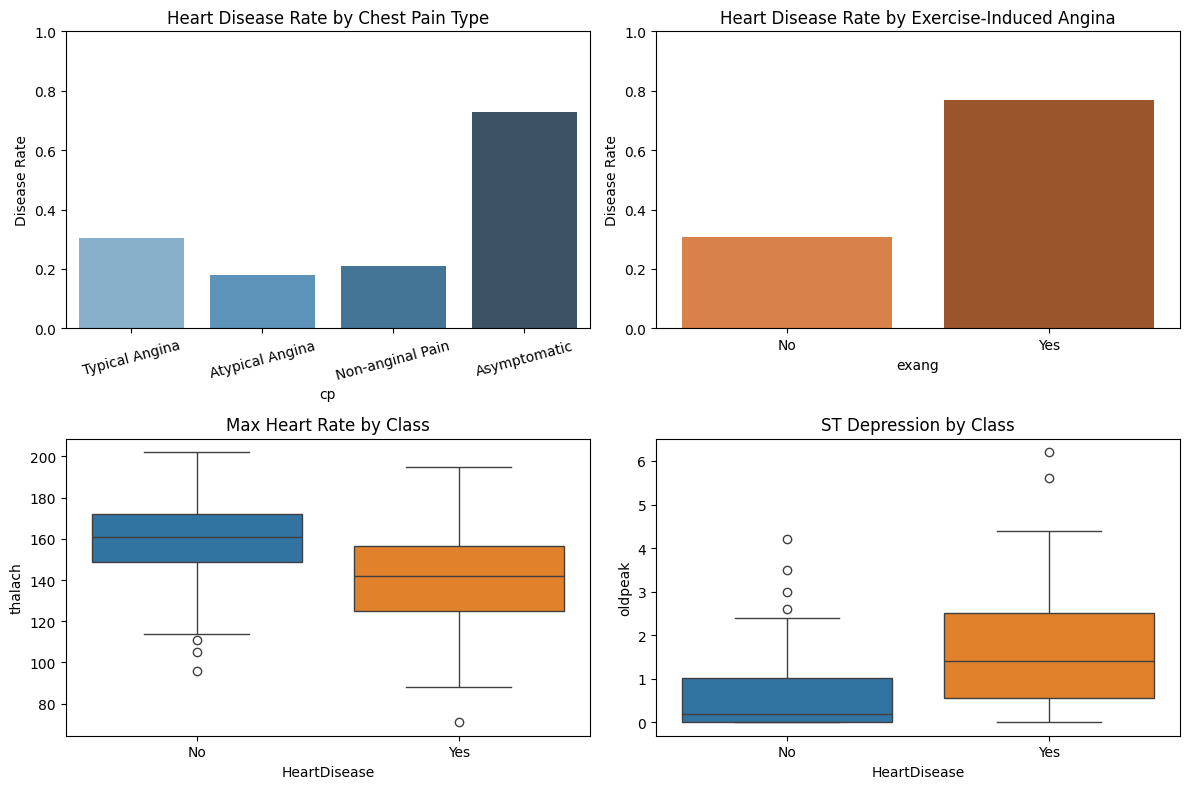

Disease rate by chest pain type:
 cp
Typical Angina      0.30
Atypical Angina     0.18
Non-anginal Pain    0.21
Asymptomatic        0.73

Disease rate by exercise angina:
 exang
No     0.31
Yes    0.77

Median max heart rate  -> No disease: 161 bpm, Disease: 142 bpm
Median ST depression   -> No disease: 0.2, Disease: 1.4

Observation: these four attributes clearly differ between the two classes, so they carry predictive signal.


In [5]:
"""
Purpose of this section:
-------------------------
Before training, SEE whether the candidate features separate healthy and sick patients.
Top row: disease rate by chest-pain type and by exercise angina.
Bottom row: distribution of max heart rate and ST depression for each class.
"""
viz = preprocessed_data.assign(DiseaseNum=(preprocessed_data["HeartDisease"] == "Yes").astype(int))
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

cp_order = ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]
cp_rate = viz.groupby("cp")["DiseaseNum"].mean().reindex(cp_order)
sns.barplot(x=cp_rate.index, y=cp_rate.values, hue=cp_rate.index, legend=False, palette="Blues_d", ax=axes[0, 0])
axes[0, 0].set_title("Heart Disease Rate by Chest Pain Type"); axes[0, 0].set_ylabel("Disease Rate"); axes[0, 0].set_ylim(0, 1)
axes[0, 0].tick_params(axis="x", rotation=15)

ex_rate = viz.groupby("exang")["DiseaseNum"].mean().reindex(["No", "Yes"])
sns.barplot(x=ex_rate.index, y=ex_rate.values, hue=ex_rate.index, legend=False, palette="Oranges_d", ax=axes[0, 1])
axes[0, 1].set_title("Heart Disease Rate by Exercise-Induced Angina"); axes[0, 1].set_ylabel("Disease Rate"); axes[0, 1].set_ylim(0, 1)

for ax, col, title in [(axes[1, 0], "thalach", "Max Heart Rate by Class"), (axes[1, 1], "oldpeak", "ST Depression by Class")]:
    sns.boxplot(data=viz, x="HeartDisease", y=col, order=["No", "Yes"], hue="HeartDisease", hue_order=["No", "Yes"], legend=False, ax=ax)
    ax.set_title(title)

plt.tight_layout(); plt.show()

print("Disease rate by chest pain type:\n", cp_rate.round(2).to_string())
print("\nDisease rate by exercise angina:\n", ex_rate.round(2).to_string())
print("\nMedian max heart rate  -> No disease: %d bpm, Disease: %d bpm" % tuple(viz.groupby("HeartDisease")["thalach"].median().reindex(["No", "Yes"])))
print("Median ST depression   -> No disease: %.1f, Disease: %.1f" % tuple(viz.groupby("HeartDisease")["oldpeak"].median().reindex(["No", "Yes"])))
print("\nObservation: these four attributes clearly differ between the two classes, so they carry predictive signal.")

### Step 4: Feature Extraction (Selecting the 4 Input Attributes)
The task allows **only 4 inputs** out of 13. Instead of guessing, three kinds of evidence are used:
1. **Correlation** of each attribute with the disease label (linear/monotonic signal).
2. **Random Forest importance** (captures non-linear effects and interactions).
3. **Cross-validated accuracy** of candidate 4-feature sets with an SVC (does the set really work?).

A fourth, practical criterion is **availability**: the deployed form must be fillable by an ordinary user.

+-----------+---------------+---------------+
| Attribute | |Correlation| | RF Importance |
+-----------+---------------+---------------+
|    thal   |     0.526     |     0.133     |
|     ca    |      0.46     |      0.12     |
|   exang   |     0.432     |     0.053     |
|  oldpeak  |     0.425     |     0.108     |
|  thalach  |     0.417     |     0.114     |
|     cp    |     0.414     |      0.12     |
|   slope   |     0.339     |     0.043     |
|    sex    |     0.277     |     0.032     |
|    age    |     0.223     |     0.089     |
|  restecg  |     0.169     |     0.021     |
|  trestbps |     0.151     |     0.076     |
|    chol   |     0.085     |      0.08     |
|    fbs    |     0.025     |      0.01     |
+-----------+---------------+---------------+


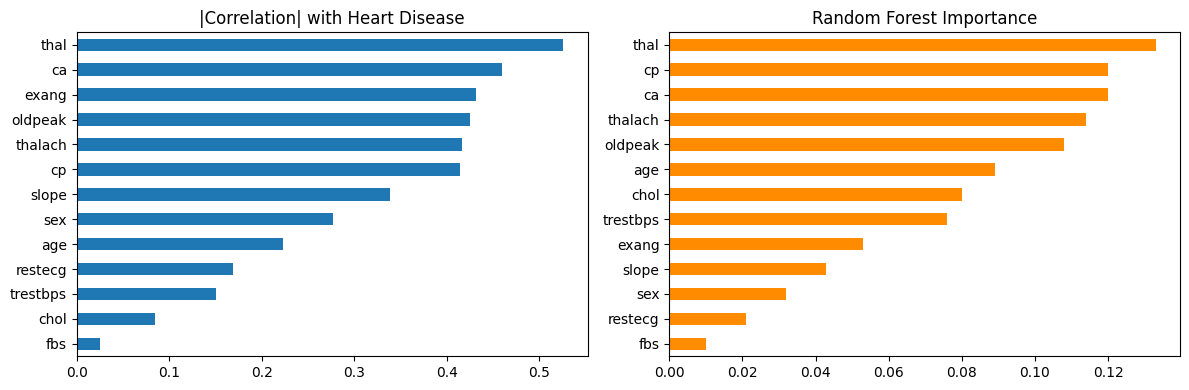

In [6]:
"""
Purpose of this section:
-------------------------
Ranks all 13 attributes and justifies the final choice of 4.
(Numeric codes from the original data are used here because correlation needs numbers.)
"""
target_numeric = (sample_data["num"] > 0).astype(int)

# Evidence 1: absolute correlation with the target
corr = (sample_data.drop(columns="num").assign(target=target_numeric)
        .corr()["target"].drop("target").abs())

# Evidence 2: Random Forest importance (needs complete rows, so drop the 6 rows with '?')
complete = sample_data.dropna()
rf = RandomForestClassifier(n_estimators=300, random_state=0)
rf.fit(complete.drop(columns="num"), (complete["num"] > 0).astype(int))
importance = pd.Series(rf.feature_importances_, index=complete.drop(columns="num").columns)

ranking = pd.DataFrame({"Correlation": corr, "RF Importance": importance}).sort_values("Correlation", ascending=False).round(3)
table = PrettyTable(); table.field_names = ["Attribute", "|Correlation|", "RF Importance"]
for name, row in ranking.iterrows(): table.add_row([name, row["Correlation"], row["RF Importance"]])
print(table)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ranking["Correlation"].sort_values().plot(kind="barh", ax=axes[0], title="|Correlation| with Heart Disease")
ranking["RF Importance"].sort_values().plot(kind="barh", ax=axes[1], title="Random Forest Importance", color="darkorange")
plt.tight_layout(); plt.show()

In [7]:
"""
Evidence 3: compare candidate 4-feature sets using 5-fold cross-validation.
The scaler sits INSIDE the pipeline, so it is re-fitted on each training fold (no data leakage).
"""
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
X_all, y_all = complete.drop(columns="num"), (complete["num"] > 0).astype(int)

candidate_sets = {
    "cp, thalach, exang, oldpeak  (CHOSEN)": ["cp", "thalach", "exang", "oldpeak"],
    "age, sex, cp, thalach": ["age", "sex", "cp", "thalach"],
    "cp, thalach, exang, sex": ["cp", "thalach", "exang", "sex"],
    "thal, ca, cp, thalach  (top-4 by importance)": ["thal", "ca", "cp", "thalach"],
    "cp, exang, oldpeak, ca": ["cp", "exang", "oldpeak", "ca"],
}
table = PrettyTable(); table.field_names = ["Candidate 4-feature set", "5-fold CV accuracy"]
for name, cols in candidate_sets.items():
    score = cross_val_score(make_pipeline(StandardScaler(), svm.SVC(gamma="auto")), X_all[cols], y_all, cv=cv).mean()
    table.add_row([name, round(score, 3)])
print(table)
print("\nDecision: all four rank in the top 6 by correlation (cp, thalach and oldpeak are also top 5 by RF importance)")
print("and all come from a basic symptom review + exercise stress test. 'ca' and 'thal' score higher but need")
print("fluoroscopy / a thallium scan, which an ordinary user cannot enter in a simple form.")

+----------------------------------------------+--------------------+
|           Candidate 4-feature set            | 5-fold CV accuracy |
+----------------------------------------------+--------------------+
|    cp, thalach, exang, oldpeak  (CHOSEN)     |       0.771        |
|            age, sex, cp, thalach             |       0.757        |
|           cp, thalach, exang, sex            |       0.764        |
| thal, ca, cp, thalach  (top-4 by importance) |       0.825        |
|            cp, exang, oldpeak, ca            |       0.825        |
+----------------------------------------------+--------------------+

Decision: all four rank in the top 6 by correlation (cp, thalach and oldpeak are also top 5 by RF importance)
and all come from a basic symptom review + exercise stress test. 'ca' and 'thal' score higher but need
fluoroscopy / a thallium scan, which an ordinary user cannot enter in a simple form.


In [8]:
"""
Final feature extraction: keep ONLY the 4 chosen inputs + the output, with readable names.
"""
selected = {"cp": "ChestPain", "thalach": "MaxHeartRate", "exang": "ExerciseAngina", "oldpeak": "STDepression"}
heart_data = preprocessed_data[list(selected.keys()) + ["HeartDisease"]].rename(columns=selected)

print("Selected attributes:", list(heart_data.columns[:-1]))
print("Missing values in selected attributes:", int(heart_data.isna().sum().sum()), "(the 6 incomplete rows are in ca/thal, which we do not use)")
print("Rows kept:", len(heart_data))
print(); print(heart_data.head())

Selected attributes: ['ChestPain', 'MaxHeartRate', 'ExerciseAngina', 'STDepression']
Missing values in selected attributes: 0 (the 6 incomplete rows are in ca/thal, which we do not use)
Rows kept: 303

          ChestPain  MaxHeartRate ExerciseAngina  STDepression HeartDisease
0    Typical Angina         150.0             No           2.3           No
1      Asymptomatic         108.0            Yes           1.5          Yes
2      Asymptomatic         129.0            Yes           2.6          Yes
3  Non-anginal Pain         187.0             No           3.5           No
4   Atypical Angina         172.0             No           1.4           No


### Step 5: Label Encoding the Sample Data (Input and Output is converted in Numeric Representation)

#### Step 5.1: Train the Label Encoder

In [9]:
"""
Purpose of this section:
-------------------------
Label Encoding converts text categories to integers. Each encoder is fitted on the
fixed list of ALL possible values, so the application phase uses the same mapping.
Only the categorical attributes need encoders (ChestPain, ExerciseAngina, HeartDisease).
MaxHeartRate and STDepression are already numeric.
"""
chestpain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-anginal Pain", "Asymptomatic"]})
exerciseangina = pd.DataFrame({"ExerciseAngina": ["No", "Yes"]})
heartdisease = pd.DataFrame({"HeartDisease": ["No", "Yes"]})

chestpain_label_encoder = LabelEncoder()
exerciseangina_label_encoder = LabelEncoder()
heartdisease_label_encoder = LabelEncoder()

chestpain_label_encoder.fit(np.ravel(chestpain))
exerciseangina_label_encoder.fit(np.ravel(exerciseangina))
heartdisease_label_encoder.fit(np.ravel(heartdisease))

# LabelEncoder sorts categories alphabetically. Show the resulting mapping:
for name, enc in [("ChestPain", chestpain_label_encoder), ("ExerciseAngina", exerciseangina_label_encoder), ("HeartDisease", heartdisease_label_encoder)]:
    print(name, "->", {cls: int(i) for i, cls in enumerate(enc.classes_)})

ChestPain -> {'Asymptomatic': 0, 'Atypical Angina': 1, 'Non-anginal Pain': 2, 'Typical Angina': 3}
ExerciseAngina -> {'No': 0, 'Yes': 1}
HeartDisease -> {'No': 0, 'Yes': 1}


#### Step 5.2: Label Encode the Output

In [10]:
"""
Purpose of this section:
-------------------------
Encodes the output (HeartDisease): "No" -> 0 and "Yes" -> 1.
"""
heart_data_encoded_output = heart_data.copy()
original_heart_data = heart_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
heart_data["encoded_heartdisease"] = heartdisease_label_encoder.transform(heart_data["HeartDisease"])
print(heart_data[["HeartDisease", "encoded_heartdisease"]].head(10))

heart_data_encoded_output["HeartDisease"] = heart_data["encoded_heartdisease"]
heart_data_encoded_output.to_csv("heart-data-encoded-output.csv", index=False, header=True)
print("\nSaved: heart-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heartdisease
0           No                     0
1          Yes                     1
2          Yes                     1
3           No                     0
4           No                     0
5           No                     0
6          Yes                     1
7           No                     0
8          Yes                     1
9          Yes                     1

Saved: heart-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [11]:
"""
Purpose of this section:
-------------------------
Encodes the categorical inputs (ChestPain, ExerciseAngina).
The numeric inputs are copied unchanged.
"""
heart_data_encoded = heart_data_encoded_output.copy()
heart_data_encoded["ChestPain"] = chestpain_label_encoder.transform(heart_data_encoded_output["ChestPain"])
heart_data_encoded["ExerciseAngina"] = exerciseangina_label_encoder.transform(heart_data_encoded_output["ExerciseAngina"])

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(heart_data_encoded.head(10))
heart_data_encoded.to_csv("heart-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

   ChestPain  MaxHeartRate  ExerciseAngina  STDepression  HeartDisease
0          3         150.0               0           2.3             0
1          0         108.0               1           1.5             1
2          0         129.0               1           2.6             1
3          2         187.0               0           3.5             0
4          1         172.0               0           1.4             0
5          1         178.0               0           0.8             0
6          0         160.0               0           3.6             1
7          0         163.0               1           0.6             0
8          0         147.0               0           1.4             1
9          0         155.0               1           3.1             1


### Step 6: Execute the Training Phase

#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [12]:
"""
Purpose of this section:
-------------------------
80% of the data trains the model, 20% is kept unseen for testing.
random_state=0 -> same split every run.
shuffle=True + stratify -> mix the rows and keep the same No/Yes ratio in both parts
(the Titanic notebook used shuffle=False; here the class ratio is preserved explicitly).
"""
training_data_encoded, testing_data_encoded = train_test_split(
    heart_data_encoded, test_size=0.2, random_state=0, shuffle=True,
    stratify=heart_data_encoded["HeartDisease"]
)
training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)
print("\nDisease share  -> train: %.2f | test: %.2f" % (training_data_encoded["HeartDisease"].mean(), testing_data_encoded["HeartDisease"].mean()))

Training Data shape: (242, 5)
Testing Data shape: (61, 5)

Disease share  -> train: 0.46 | test: 0.46


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [13]:
input_vector_train = training_data_encoded.iloc[:, :-1]     # the 4 input columns
output_label_train = training_data_encoded.iloc[:, -1]      # the HeartDisease column

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (242, 4)
Output labels (train) shape: (242,)


### Step 6.3: Scale the Numeric Features (NEW)
SVC (and Logistic Regression) work with **distances / weighted sums**. MaxHeartRate is around 150 while ExerciseAngina is 0 or 1, so without scaling the big numbers would dominate. `StandardScaler` rewrites every column as `(x - mean) / standard deviation`.

**Important:** the scaler is fitted on the **training data only**. Fitting on all data would leak information about the test set.

In [14]:
scaler = StandardScaler()
input_vector_train_scaled = pd.DataFrame(scaler.fit_transform(input_vector_train),
                                         columns=input_vector_train.columns, index=input_vector_train.index)

print("Learned from training data only:")
print("  means:", dict(zip(input_vector_train.columns, scaler.mean_.round(2))))
print("  stds :", dict(zip(input_vector_train.columns, scaler.scale_.round(2))))
print("\nScaled training inputs (first 5 rows):")
print(input_vector_train_scaled.head().round(3))

Learned from training data only:
  means: {'ChestPain': np.float64(0.91), 'MaxHeartRate': np.float64(148.56), 'ExerciseAngina': np.float64(0.31), 'STDepression': np.float64(1.08)}
  stds : {'ChestPain': np.float64(1.03), 'MaxHeartRate': np.float64(23.11), 'ExerciseAngina': np.float64(0.46), 'STDepression': np.float64(1.2)}

Scaled training inputs (first 5 rows):
     ChestPain  MaxHeartRate  ExerciseAngina  STDepression
111     -0.886        -0.197           1.478         0.102
52      -0.886         0.192          -0.677        -0.900
173     -0.886         0.365          -0.677         0.102
138     -0.886        -0.803           1.478         0.436
11       0.084         0.192          -0.677         0.186


### 6.4: Train the Support Vector Classifier

In [15]:
"""
Purpose of this section:
-------------------------
Trains the SVC. It finds the boundary that separates "disease" and "no disease"
with the widest possible margin (using the RBF kernel for curved boundaries).
"""
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train_scaled, np.ravel(output_label_train))
print(svc_model)
print("Support vectors used:", svc_model.n_support_.sum(), "of", len(input_vector_train_scaled), "training rows")



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)
Support vectors used: 133 of 242 training rows


### Step 6.5: Save the Trained Model

In [16]:
"""
Saves the model AND the preprocessing objects. The deployed app needs all three,
because new user input must be encoded and scaled exactly as the training data was.
"""
pickle.dump(svc_model, open("svc_trained_model.pkl", "wb"))
pickle.dump(scaler, open("scaler.pkl", "wb"))
pickle.dump({"ChestPain": chestpain_label_encoder, "ExerciseAngina": exerciseangina_label_encoder,
             "HeartDisease": heartdisease_label_encoder}, open("label_encoders.pkl", "wb"))
print("Saved: svc_trained_model.pkl, scaler.pkl, label_encoders.pkl")

Saved: svc_trained_model.pkl, scaler.pkl, label_encoders.pkl


### Step 6.6: Compare SVC vs. Logistic Regression vs. Decision Tree


Model Comparison:
+---------------------+----------+-----------+--------+----------+---------------+
|        Model        | Accuracy | Precision | Recall | F1-score | 5-fold CV Acc |
+---------------------+----------+-----------+--------+----------+---------------+
|   SVC (gamma=auto)  |   0.8    |    0.84   |  0.8   |   0.79   |      0.79     |
| Logistic Regression |   0.89   |    0.89   |  0.89  |   0.88   |      0.79     |
|    Decision Tree    |   0.69   |    0.69   |  0.69  |   0.69   |      0.69     |
+---------------------+----------+-----------+--------+----------+---------------+


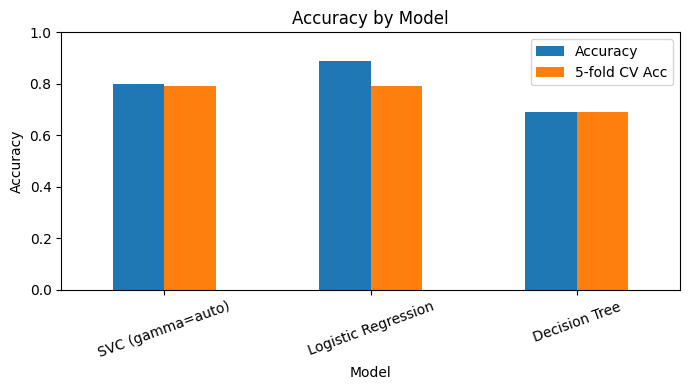

In [17]:
"""
Purpose of this section:
-------------------------
Trains Logistic Regression and Decision Tree on the SAME scaled training data and compares
all three on (a) the held-out test set and (b) 5-fold cross-validation over all 303 rows.
The model that is saved and deployed is still the SVC, as in the Titanic notebook.
"""
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
input_vector_test_scaled = pd.DataFrame(scaler.transform(input_vector_test), columns=input_vector_test.columns, index=input_vector_test.index)

candidate_models = {
    "SVC (gamma=auto)": svc_model,
    "Logistic Regression": LogisticRegression(random_state=0, max_iter=1000).fit(input_vector_train_scaled, np.ravel(output_label_train)),
    "Decision Tree": DecisionTreeClassifier(random_state=0).fit(input_vector_train_scaled, np.ravel(output_label_train)),
}
fresh_models = {
    "SVC (gamma=auto)": svm.SVC(gamma="auto", random_state=0),
    "Logistic Regression": LogisticRegression(random_state=0, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=0),
}
X_cv, y_cv = heart_data_encoded.iloc[:, :-1], heart_data_encoded.iloc[:, -1]

rows = []
for name, mdl in candidate_models.items():
    preds = mdl.predict(input_vector_test_scaled)
    rep = classification_report(output_label_test, preds, output_dict=True, zero_division=0)["weighted avg"]
    cv_acc = cross_val_score(make_pipeline(StandardScaler(), fresh_models[name]), X_cv, y_cv, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
    rows.append({"Model": name, "Accuracy": round(accuracy_score(output_label_test, preds), 2),
                 "Precision": round(rep["precision"], 2), "Recall": round(rep["recall"], 2),
                 "F1-score": round(rep["f1-score"], 2), "5-fold CV Acc": round(cv_acc, 2)})

comparison_df = pd.DataFrame(rows)
table = PrettyTable(); table.field_names = list(comparison_df.columns)
for _, r in comparison_df.iterrows(): table.add_row(list(r))
print("\nModel Comparison:")
print(table)

comparison_df.set_index("Model")[["Accuracy", "5-fold CV Acc"]].plot(kind="bar", figsize=(7, 4), title="Accuracy by Model", ylim=(0, 1))
plt.ylabel("Accuracy"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### Step 7: Execute the Testing Phase

#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [18]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (61, 4)
Output labels (test) shape: (61,)


### Step 7.2: Load the Saved Model

In [19]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))
loaded_scaler = pickle.load(open("scaler.pkl", "rb"))
print("Model and scaler loaded from disk")

Model and scaler loaded from disk


### Step 7.3: Evaluate the Machine Learning Model

#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [20]:
"""
The test inputs are scaled with the scaler learned on TRAINING data (transform only, never fit).
"""
input_vector_test_scaled = pd.DataFrame(loaded_scaler.transform(input_vector_test), columns=input_vector_test.columns, index=input_vector_test.index)
model_predictions = model.predict(input_vector_test_scaled)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model (first 15 test rows):")
print("===============================================================\n")
print(model_predictions.head(15))



Predictions Returned by svc_trained_model (first 15 test rows):

     ChestPain  MaxHeartRate  ExerciseAngina  STDepression  HeartDisease  \
125          1         175.0               0           0.6             0   
83           2         150.0               1           1.6             1   
53           1         188.0               0           0.0             0   
45           2         165.0               0           2.5             1   
248          0         168.0               0           1.0             1   
211          3         182.0               1           3.8             1   
36           0         120.0               1           2.5             1   
106          0         162.0               1           0.0             1   
120          0         150.0               1           0.0             1   
31           0         160.0               1           1.4             1   
156          0         173.0               1           1.6             1   
157          0       

### Step 7.4: Calculate the Accuracy Score

In [21]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.8


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                precision    recall  f1-score   support

No Disease (0)       0.74      0.97      0.84        33
   Disease (1)       0.94      0.61      0.74        28

      accuracy                           0.80        61
     macro avg       0.84      0.79      0.79        61
  weighted avg       0.84      0.80      0.79        61


Confusion Matrix:

                    Predicted: No Disease  Predicted: Disease
Actual: No Disease                     32                   1
Actual: Disease                        11                  17

True Negatives=32, False Positives=1, False Negatives=11, True Positives=17


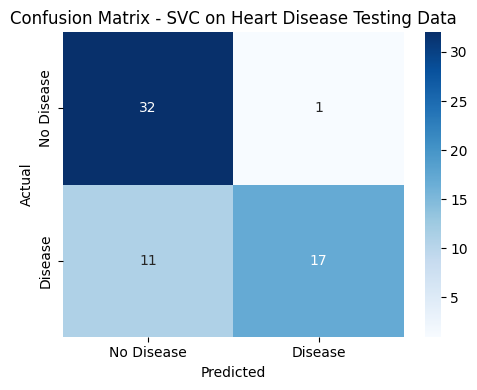

In [22]:
"""
Accuracy alone can hide problems. In medical screening a FALSE NEGATIVE (a sick patient
labelled healthy) is the most dangerous mistake, so recall of the "Disease" class matters most.
"""
print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Disease (0)", "Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(conf_matrix, index=["Actual: No Disease", "Actual: Disease"],
                              columns=["Predicted: No Disease", "Predicted: Disease"])
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

tn, fp, fn, tp = conf_matrix.ravel()
print(f"\nTrue Negatives={tn}, False Positives={fp}, False Negatives={fn}, True Positives={tp}")

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"], yticklabels=["No Disease", "Disease"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout(); plt.show()

### Step 8: Execute the Application Phase

#### Step 8.1: Take Input from User

In [23]:
"""
Takes the 4 inputs of a new patient. A demo patient is pre-filled so the notebook runs
top-to-bottom. For interactive use, replace the 4 lines with:
    chestpain_input = input("Chest pain type (Typical Angina, Atypical Angina, Non-anginal Pain, Asymptomatic): ").strip()
    maxheartrate_input = float(input("Maximum heart rate achieved (bpm): "))
    exerciseangina_input = input("Exercise-induced angina (Yes, No): ").strip()
    stdepression_input = float(input("ST depression induced by exercise (0 - 6.5): "))
"""
chestpain_input = "Asymptomatic"
maxheartrate_input = 120
exerciseangina_input = "Yes"
stdepression_input = 2.5

print(f"ChestPain: {chestpain_input}, MaxHeartRate: {maxheartrate_input}, ExerciseAngina: {exerciseangina_input}, STDepression: {stdepression_input}")

ChestPain: Asymptomatic, MaxHeartRate: 120, ExerciseAngina: Yes, STDepression: 2.5


### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [24]:
user_input = pd.DataFrame({
    "ChestPain": [chestpain_input],
    "MaxHeartRate": [maxheartrate_input],
    "ExerciseAngina": [exerciseangina_input],
    "STDepression": [stdepression_input],
})
print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

      ChestPain  MaxHeartRate ExerciseAngina  STDepression
0  Asymptomatic           120            Yes           2.5


### Step 8.3: Label Encoding (and Scaling) of Feature Vector - Exactly the Same as Training Data

In [25]:
unseen_data_features = user_input.copy()
unseen_data_features["ChestPain"] = chestpain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["ExerciseAngina"] = exerciseangina_label_encoder.transform(user_input["ExerciseAngina"])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)

# Same scaling as training (transform only)
unseen_data_scaled = pd.DataFrame(loaded_scaler.transform(unseen_data_features), columns=unseen_data_features.columns)
print("\nUser Input Scaled Feature Vector:")
print(unseen_data_scaled.round(3))



User Input Encoded Feature Vector:

   ChestPain  MaxHeartRate  ExerciseAngina  STDepression
0          0           120               1           2.5

User Input Scaled Feature Vector:
   ChestPain  MaxHeartRate  ExerciseAngina  STDepression
0     -0.886        -1.236           1.478         1.188


### Step 8.4: Load the Saved Model

In [26]:
model = pickle.load(open("svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction

#### Step 8.5.1: Apply Model on the Feature Vector of the unseen instance and return Prediction to the User

In [27]:
predicted_class = model.predict(unseen_data_scaled)[0]
prediction = "HEART DISEASE LIKELY" if predicted_class == 1 else "NO HEART DISEASE DETECTED"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)
print("(Educational demo only - not a medical diagnosis.)")

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+
(Educational demo only - not a medical diagnosis.)


### Step 9: Execute the Feedback Phase

#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [28]:
"""
Step 9.1: In a real deployment, feedback comes from doctors and users. Here the
mistakes the model made on the test set are listed, so they can be reviewed
by a domain expert (what kind of patients does the model get wrong?).
"""
errors = testing_data_encoded[testing_data_encoded["HeartDisease"] != testing_data_encoded["Predictions"]].copy()
errors["ChestPain"] = chestpain_label_encoder.inverse_transform(errors["ChestPain"])
errors["ExerciseAngina"] = exerciseangina_label_encoder.inverse_transform(errors["ExerciseAngina"])
errors["Error type"] = np.where(testing_data_encoded.loc[errors.index, "HeartDisease"] == 1, "FALSE NEGATIVE (missed disease)", "FALSE POSITIVE (false alarm)")
print("Misclassified test patients:", len(errors), "of", len(testing_data_encoded))
print(errors[["ChestPain", "MaxHeartRate", "ExerciseAngina", "STDepression", "Error type"]].to_string())
print("\nDomain-expert question: do the false negatives look like 'typical' patients with mild symptoms? If so,")
print("4 attributes may not hold enough information, and the missing ones (ca, thal, age) could help.")

Misclassified test patients:

 12 of 61
            ChestPain  MaxHeartRate ExerciseAngina  STDepression                       Error type
83   Non-anginal Pain         150.0            Yes           1.6  FALSE NEGATIVE (missed disease)
45   Non-anginal Pain         165.0             No           2.5  FALSE NEGATIVE (missed disease)
248      Asymptomatic         168.0             No           1.0  FALSE NEGATIVE (missed disease)
211    Typical Angina         182.0            Yes           3.8  FALSE NEGATIVE (missed disease)
157      Asymptomatic         171.0             No           0.0  FALSE NEGATIVE (missed disease)
250      Asymptomatic         126.0            Yes           1.5     FALSE POSITIVE (false alarm)
184      Asymptomatic         161.0             No           0.0  FALSE NEGATIVE (missed disease)
69   Non-anginal Pain         147.0             No           3.6  FALSE NEGATIVE (missed disease)
267  Non-anginal Pain         134.0             No           2.2  FALSE NEGATIVE (missed disease)
8        A

#### Step 9.2: Make a List of Potential Improvements

In [29]:
improvements = [
    "Add more attributes (e.g. ca, thal, age, sex). Cross-validation in Step 4 showed ca/thal raise accuracy, at the cost of a harder-to-fill form",
    "Use all four UCI sites (Cleveland, Hungarian, Switzerland, VA) for more training data than 303 rows",
    "Tune SVC hyper-parameters (C, gamma) with GridSearchCV instead of the default gamma='auto'",
    "Use One-Hot Encoding for ChestPain: Label Encoding gives categories an artificial order",
    "Optimise for recall of the Disease class (e.g. class_weight='balanced') since missed disease is the costly error",
    "Compare more models (Random Forest, Gradient Boosting, k-NN)",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add more attributes (e.g. ca, thal, age, sex). Cross-validation in Step 4 showed ca/thal raise accuracy, at the cost of a harder-to-fill form
2. Use all four UCI sites (Cleveland, Hungarian, Switzerland, VA) for more training data than 303 rows
3. Tune SVC hyper-parameters (C, gamma) with GridSearchCV instead of the default gamma='auto'
4. Use One-Hot Encoding for ChestPain: Label Encoding gives categories an artificial order
5. Optimise for recall of the Disease class (e.g. class_weight='balanced') since missed disease is the costly error
6. Compare more models (Random Forest, Gradient Boosting, k-NN)


#### Step 9.3: Improve the Model Based on Feedback

In [30]:
"""
Step 9.3: A first improvement experiment aimed at the main weakness found above (missed disease cases).
Three SVC variants are compared with 5-fold cross-validation on all 303 rows (scaler inside the pipeline).
The deployed model is NOT replaced here - this only shows what is possible.
"""
from sklearn.model_selection import cross_validate, GridSearchCV
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
X_all_enc, y_all_enc = heart_data_encoded.iloc[:, :-1], heart_data_encoded.iloc[:, -1]

grid = GridSearchCV(make_pipeline(StandardScaler(), svm.SVC(class_weight="balanced", random_state=0)),
                    {"svc__C": [0.1, 1, 10], "svc__gamma": ["auto", 0.05, 0.1, 0.5]}, cv=cv5, scoring="recall")
grid.fit(X_all_enc, y_all_enc)

variants = {
    "Current SVC (deployed)": make_pipeline(StandardScaler(), svm.SVC(gamma="auto", random_state=0)),
    "SVC + class_weight='balanced'": make_pipeline(StandardScaler(), svm.SVC(gamma="auto", class_weight="balanced", random_state=0)),
    f"SVC tuned for recall {grid.best_params_}": grid.best_estimator_,
}
table = PrettyTable(); table.field_names = ["Variant", "CV Accuracy", "CV Recall (Disease)"]
for name, pipe in variants.items():
    res = cross_validate(pipe, X_all_enc, y_all_enc, cv=cv5, scoring=["accuracy", "recall"])
    table.add_row([name, round(res["test_accuracy"].mean(), 3), round(res["test_recall"].mean(), 3)])
print(table)
print("\nReading the result: class weighting alone changes little. Tuning for recall catches more sick patients")
print("but lowers overall accuracy - a precision/recall trade-off. (The tuned row is slightly optimistic because the")
print("same folds were used to choose the parameters.) With only 4 inputs there is a ceiling on performance;")
print("the larger gains would come from the extra attributes listed in Step 9.2.")

+--------------------------------------------------------+-------------+---------------------+
|                        Variant                         | CV Accuracy | CV Recall (Disease) |
+--------------------------------------------------------+-------------+---------------------+
|                 Current SVC (deployed)                 |    0.785    |        0.654        |
|             SVC + class_weight='balanced'              |    0.782    |        0.662        |
| SVC tuned for recall {'svc__C': 10, 'svc__gamma': 0.5} |    0.749    |        0.748        |
+--------------------------------------------------------+-------------+---------------------+

Reading the result: class weighting alone changes little. Tuning for recall catches more sick patients
but lowers overall accuracy - a precision/recall trade-off. (The tuned row is slightly optimistic because the
same folds were used to choose the parameters.) With only 4 inputs there is a ceiling on performance;
the larger gains wo

## Step 10: Deploy Your Model as a Public Web App

Running the notebook only lets *you* use the model while Jupyter is open. Deployment turns it into a **live website** that anyone can open in a browser. The same process as the Titanic project is used: **GitHub + Streamlit Community Cloud** (free).

#### Step 10.1: Why Deploy a Model?
A trained model is useful only if other people can access it. A small web app lets non-technical users (teachers, classmates, doctors) use the model without Python or Jupyter.

#### Step 10.2: Create a GitHub Account and Repository
1. Sign up at **https://github.com** (free).
2. Click **+ -> New repository**, name it e.g. `heart-disease-app`, keep it **Public**, click **Create repository**.
3. Click **Add file -> Upload files** and drag in these 5 files from the `heart-disease-app` folder, then **Commit changes**:
   `app.py`, `requirements.txt`, `svc_trained_model.pkl`, `scaler.pkl`, `label_encoders.pkl`

#### Step 10.3: The Web App (`app.py`)
`app.py` follows exactly Steps 8.1 to 8.5 of this notebook, but with Streamlit widgets instead of `input()`:
1. Loads the three `.pkl` files (model, scaler, label encoders).
2. Shows `st.selectbox` for chest pain and exercise angina, and `st.number_input` / `st.slider` for max heart rate and ST depression.
3. On button click: builds the DataFrame -> label-encodes -> scales -> `model.predict(...)` -> shows `st.success` / `st.error`.

`requirements.txt` lists `streamlit`, `scikit-learn` (the **same version used to train**, because pickle files are version-sensitive), `pandas`, `numpy`.

#### Step 10.4: Create a Streamlit Community Cloud Account
Go to **https://share.streamlit.io** -> **Sign in with GitHub** -> authorize access.

#### Step 10.5: Deploy Your App
1. **Create app -> Deploy a public app from GitHub**.
2. Repository: `<your-username>/heart-disease-app`, Branch: `main`, Main file path: `app.py`.
3. Under **Advanced settings** choose **Python 3.12**, then click **Deploy**. After a minute or two you get a public URL `https://<something>.streamlit.app`.

#### Step 10.6: Troubleshooting Common Issues
- **`ModuleNotFoundError` / install fails:** pick Python 3.11 or 3.12 in **Settings -> General -> Python version**.
- **Version warning or error when loading a `.pkl`:** the scikit-learn version in `requirements.txt` must match the version that created the pickles. Re-run this notebook (it regenerates the files) and pin your own version.
- **`requirements.txt` ignored:** it must be in the same folder as `app.py`.
- **App stuck on "in the oven":** open **Manage app** to read the build log, fix the error, then reboot.

#### Step 10.7: Share Your Live Link
Add the URL to your README / report and share it. Anyone can use the model with nothing to install.

## Conclusion

In [31]:
svc_row = comparison_df[comparison_df["Model"].str.startswith("SVC")].iloc[0]
print(f"""Conclusion
==========
Using only 4 inputs (chest pain type, maximum heart rate, exercise-induced angina and ST depression),
the Support Vector Classifier reached {model_accuracy_score:.2f} accuracy on the held-out test set
({svc_row['5-fold CV Acc']:.2f} in 5-fold cross-validation, which is the more reliable figure for 303 rows).
On the test set it found {tp} of {tp + fn} patients with heart disease (recall {tp/(tp+fn):.2f}) and raised {fp} false alarm(s).
The model is an educational demonstration: more attributes, more data and tuning (Step 9.2) would be
needed before it could support any real clinical decision.""")

Conclusion
Using only 4 inputs (chest pain type, maximum heart rate, exercise-induced angina and ST depression),
the Support Vector Classifier reached 0.80 accuracy on the held-out test set
(0.79 in 5-fold cross-validation, which is the more reliable figure for 303 rows).
On the test set it found 17 of 28 patients with heart disease (recall 0.61) and raised 1 false alarm(s).
The model is an educational demonstration: more attributes, more data and tuning (Step 9.2) would be
needed before it could support any real clinical decision.
